## 3.3.1. RQ1 — Mở rộng Độ phủ & Quy mô Người chơi

### 1. Câu hỏi nghiên cứu

> “Số lượng ngôn ngữ và hệ điều hành được hỗ trợ có mối liên hệ như thế nào với lượng người sở hữu ước tính, và mối liên hệ này thay đổi ra sao khi xét đến thể loại và tuổi đời game?”

### 2. Động cơ nghiên cứu

Câu hỏi này đáng nghiên cứu vì việc mở rộng hỗ trợ ngôn ngữ và hệ điều hành cần nguồn lực, trong khi mối liên hệ với quy mô sở hữu ước tính có thể khác theo thể loại và tuổi đời game. Hiểu được các khác biệt này giúp tránh áp dụng một chiến lược hỗ trợ chung cho mọi nhóm game.

**Các bên quan tâm:** Nhà phát triển, nhà phát hành, nhóm bản địa hóa (localization), nhóm kiểm thử tương thích (QA), nhà phân tích danh mục game và người mua game.

**Giá trị thực tiễn:** Kết quả có thể hỗ trợ ưu tiên ngôn ngữ/nền tảng để đầu tư, lựa chọn nhóm thể loại phù hợp để benchmark và diễn giải `estimated_owners` theo bối cảnh. Đây là nghiên cứu quan sát về mối liên hệ, không kết luận hỗ trợ nhiều ngôn ngữ/hệ điều hành gây tăng số người sở hữu thực tế.

### 3. Thuộc tính sử dụng và tích hợp dữ liệu

| Thuộc tính | Nguồn dữ liệu | Vai trò trong phân tích |
|---|---|---|
| `appid` / `appID` | Kaggle CSV và HF parquet | Khóa nối, định danh game và đơn vị phân tích. |
| `supported_languages` | Kaggle CSV | Nguồn tạo `language_count`. |
| `windows`, `mac`, `linux` | HF parquet | Cờ hỗ trợ hệ điều hành; nguồn chính tạo `platform_count` cho game nối được. |
| `os` | Kaggle CSV | Đối chiếu số nền tảng và tính `platform_count` dự phòng cho game không khớp HF. |
| `estimated_owners` | Kaggle CSV | Kết quả dạng khoảng; cần quy tắc giá trị đại diện. |
| `genres`, `release_date`, `price` | Kaggle CSV | Phân tầng/điều chỉnh theo thể loại, tuổi đời và giá. |

**Tích hợp D1:** Nối `steam_games_mar2025.csv` với `hf_steam_games_dataset_train.parquet` theo `appid`/`appID` sau khi chuẩn hóa kiểu khóa. Kiểm tra khóa duy nhất ở mỗi nguồn và dùng nối trái từ CSV chính để giữ đơn vị phân tích. Kiểm tra trên dữ liệu hiện có cho thấy 88.813/89.618 game khớp (99,1%); 805 game không khớp dùng danh sách `os` trong CSV làm nguồn dự phòng. Với game khớp, tính số hệ điều hành từ ba cờ `windows`, `mac`, `linux`; đối chiếu cho thấy số nền tảng giữa hai nguồn khác nhau ở 429 game (0,5% số game khớp). Các thuộc tính còn lại lấy từ CSV chính; báo cáo độ phủ nối và bất đồng nguồn trong kết quả.

### 4. Giả thuyết nghiên cứu

- **H1:** `language_count` và `platform_count` có mối liên hệ với `owner_midpoint` ở cấp game; không diễn giải là quan hệ nhân quả.
- **H2:** Mức mối liên hệ giữa độ phủ hỗ trợ và lượng owner khác nhau giữa các nhóm `genres`.
- **H3:** Mức mối liên hệ thay đổi theo `game_age` khi xem xét `genres` và `price`.

### 5. Tiêu chí chiều sâu phân tích — dự kiến

| Tiêu chí | Phương pháp dự kiến | Mục tiêu |
|---|---|---|
| **D1 — Kết hợp dữ liệu** | Nối trái theo mã game (88.813/89.618 khớp); dùng ba cờ HF cho game khớp, dùng `os` CSV cho 805 game không khớp; đối chiếu số nền tảng (429 bất đồng). | Bổ sung và kiểm chứng thông tin nền tảng từ hai nguồn, đồng thời ghi nhận độ phủ và các trường hợp không khớp. |
| **D2 — Tái cấu trúc / Thời gian** | Dự kiến `explode()` `supported_languages` để tổng hợp ngôn ngữ; tính tuổi từ mốc chụp dữ liệu đã xác nhận. | Biểu diễn danh sách ngôn ngữ theo dạng dài (long) và đưa tuổi đời vào so sánh. |
| **D3 — Biến dẫn xuất** | Dự kiến tạo `language_count`, `platform_count` (đếm cờ `windows`/`mac`/`linux` từ HF cho game khớp; dùng `os` cho game không khớp), `owner_midpoint`, `game_age`; các khoảng `estimated_owners` hiện có đều hữu hạn. Trung điểm (midpoint) chỉ là giá trị đại diện xấp xỉ cho mỗi khoảng `estimated_owners`, không phải số người sở hữu chính xác. | Định lượng độ phủ, số người sở hữu đại diện và tuổi game với định nghĩa rõ ràng. |
| **D4 — Kiểm soát yếu tố gây nhiễu** | Xem xét `genres`, `price`, `game_age` qua phân tầng/điều chỉnh phù hợp. | Đánh giá mối liên hệ có điều kiện; không tuyên bố đã loại bỏ mọi nhiễu. |
| **D5 — Định lượng độ bất định** | Spearman Correlation và Bootstrap Confidence Interval 95% theo game; báo effect size và cỡ mẫu (N). | Định lượng độ lớn và bất định của mối liên hệ/khác biệt nhóm. |
| **D6 — Kiểm tra độ bền vững** | So sánh cách biểu diễn `estimated_owners`, cách phân nhóm tuổi đời và quy tắc nhận diện/xử lý giá trị ngoại lệ. | Kiểm tra độ ổn định với các giả định và quy tắc xử lý. |

### 6. Giới hạn nghiên cứu

`estimated_owners` là khoảng ước tính, không phải số người chơi. Hai nguồn được nối theo mã game; cần báo độ phủ nối và kiểm tra khóa duy nhất, vì các bản ghi không khớp sẽ phải dùng `os` từ CSV làm nguồn dự phòng. Số nền tảng giữa `os` và các cờ HF có thể khác do thời điểm hoặc cách ghi nhận, nên cần báo cáo bất đồng thay vì xem hai nguồn là hoàn toàn tương đương. `supported_languages` và `os` là chuỗi biểu diễn list; có 182 list ngôn ngữ rỗng, cần phân biệt không khai báo với không hỗ trợ. `genres` là đa nhãn và `game_age` cần mốc thời gian tham chiếu đã xác nhận. Chỉ diễn giải mối liên hệ.


## 3.3.2. RQ2 — Quy mô đánh giá và lượng người sở hữu

### 1. Câu hỏi nghiên cứu

> “Số lượng ngôn ngữ và hệ điều hành được hỗ trợ có mối liên hệ như thế nào với lượng người sở hữu ước tính, và mối liên hệ này thay đổi ra sao khi xét đến thể loại và tuổi đời game?”

### 2. Động cơ nghiên cứu

Số lượt đánh giá là một cách đo mức độ người chơi để lại phản hồi cho từng game, còn tỷ lệ tích cực tóm tắt chiều hướng phản hồi. So sánh hai chỉ số theo quy mô sở hữu, tuổi game và thể loại giúp mô tả game nào có nhiều đánh giá hơn và liệu mức độ tích cực có đi cùng số lượt đánh giá hay không. Phân tích ở cấp game nên không đại diện cho từng người chơi và không kết luận quan hệ nhân quả.

**Các bên quan tâm:** Nhà phát triển, nhà phát hành, nhóm chăm sóc cộng đồng, nhà phân tích danh mục game và người mua game.

**Giá trị thực tiễn:** Kết quả có thể giúp so sánh mức độ phản hồi và tỷ lệ đánh giá tích cực giữa các game/ thể loại, đồng thời cho biết mối liên hệ này còn thấy được sau khi xem xét quy mô sở hữu và tuổi game hay không. Đây là quan sát ở cấp game, không chứng minh nguyên nhân.

### 3. Thuộc tính sử dụng

| Thuộc tính | Nguồn dữ liệu | Vai trò trong phân tích |
|---|---|---|
| `appid` | Chính — Kaggle CSV | Định danh game và đơn vị lấy mẫu. |
| `num_reviews_total` | Chính — Kaggle CSV | Số lượt đánh giá; giá trị `-1` không được coi là số đếm hợp lệ. |
| `pct_pos_total` | Chính — Kaggle CSV | Tỷ lệ đánh giá tích cực; `-1` không được coi là tỷ lệ hợp lệ. |
| `estimated_owners`, `release_date` | Chính — Kaggle CSV | Quy mô sở hữu ước tính và tuổi game dùng làm yếu tố giải thích/kiểm soát. |
| `genres` | Chính — Kaggle CSV | Nhóm so sánh; game có thể thuộc nhiều thể loại. |

### 4. Giả thuyết nghiên cứu

- **H1:** Số lượt đánh giá có mối liên hệ dương với quy mô sở hữu ước tính và tuổi game sau khi xem xét thể loại.
- **H2:** Mối liên hệ giữa số lượt đánh giá và tỷ lệ đánh giá tích cực khác nhau theo thể loại sau khi xem xét quy mô sở hữu và tuổi game.
- **H3:** Các mối liên hệ chính vẫn cùng chiều khi loại riêng 1% game có số lượt đánh giá cao nhất; đây là kiểm tra độ bền, không phải quy tắc xóa dữ liệu mặc định.

### 5. Tiêu chí chiều sâu phân tích — dự kiến

| Tiêu chí | Phương pháp dự kiến | Mục tiêu |
|---|---|---|
| **D2 — Tái cấu trúc / Thời gian** | Tách danh sách `genres` thành bảng phụ để tóm tắt theo thể loại; giữ khóa game để một game không bị tính lặp trong mô hình tổng thể. | So sánh nhóm thể loại mà vẫn xác định đúng đơn vị phân tích. |
| **D3 — Biến dẫn xuất** | Dùng `log1p(num_reviews_total)` và `log1p(owner_midpoint)` để giảm lệch phải; tính `game_age` đến 31/03/2025. | Đưa biến đếm và quy mô sở hữu lệch mạnh về thang dễ mô hình hóa. |
| **D4 — Kiểm soát yếu tố gây nhiễu** | Hồi quy ở cấp game, đồng thời đưa quy mô sở hữu, tuổi game và cờ thể loại vào mô hình; mô hình thứ hai thêm tương tác giữa log lượt đánh giá và thể loại. | Ước lượng mối liên hệ có điều kiện; không diễn giải là nhân quả. |
| **D5 — Định lượng độ bất định** | Hồi quy OLS với sai số chuẩn HC3 và khoảng tin cậy 95%; báo cỡ mẫu và hệ số theo đơn vị dễ hiểu. | Cho biết độ lớn và mức bất định, có xét phương sai sai số không đồng đều. |
| **D6 — Kiểm tra độ bền vững** | Lặp lại mô hình sau khi giới hạn 1% giá trị `num_reviews_total` cao nhất; đối chiếu hướng/độ lớn hệ số. | Kiểm tra kết quả có bị chi phối bởi vài game có lượng đánh giá rất lớn hay không. |

### 6. Giới hạn nghiên cứu

CSV có 89.618 game. `num_reviews_total` và `pct_pos_total` dùng `-1` cho 36.419 game; đây không phải số đếm hay tỷ lệ hợp lệ nên loại khỏi các mô hình cần hai biến này, không đổi thành 0. Chỉ 53.199 game có cả hai chỉ số hợp lệ. `num_reviews_total` không khớp `positive + negative` ở phần lớn dòng, vì vậy phân tích dùng trực tiếp hai trường tổng hợp được yêu cầu và không tự dựng lại tỷ lệ từ các cột thành phần. `estimated_owners` cũng chỉ là khoảng ước tính; game có nhiều thể loại có thể nằm trong nhiều nhóm. Kết quả mô tả mối liên hệ ở cấp game và phụ thuộc vào định nghĩa của nguồn dữ liệu.


In [1]:
from pathlib import Path
import pandas as pd

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Không tìm thấy data/raw từ thư mục hiện tại hoặc thư mục cha.")
raw_dir = project_root / "data" / "raw"
main_path = raw_dir / "steam_games_mar2025.csv" if (raw_dir / "steam_games_mar2025.csv").is_file() else None
if main_path is None:
    raise FileNotFoundError("Không tìm thấy tệp CSV dữ liệu chính trong data/raw.")
rq2_columns = ["appid", "num_reviews_total", "pct_pos_total", "positive", "negative", "estimated_owners", "release_date", "genres"]
header = pd.read_csv(main_path, nrows=0).columns
missing = sorted(set(rq2_columns) - set(header))
if missing:
    raise KeyError(f"Thiếu thuộc tính cần cho RQ2 trong CSV chính: {missing}")
rq2_source = pd.read_csv(main_path, usecols=rq2_columns)
valid_reviews = rq2_source["num_reviews_total"].ge(0) & rq2_source["pct_pos_total"].between(0, 100)
owner_bounds = rq2_source["estimated_owners"].astype("string").str.extract(r"^\s*([\d,]+)\s*-\s*([\d,]+)\s*$")
owner_low = pd.to_numeric(owner_bounds[0].str.replace(",", "", regex=False), errors="coerce")
owner_high = pd.to_numeric(owner_bounds[1].str.replace(",", "", regex=False), errors="coerce")
review_checks = pd.DataFrame([
    {"Kiểm tra": "Tổng số game", "Kết quả": len(rq2_source)},
    {"Kiểm tra": "Thiếu ở các cột sử dụng", "Kết quả": int(rq2_source[rq2_columns].isna().sum().sum())},
    {"Kiểm tra": "Mã game trùng", "Kết quả": int(rq2_source["appid"].duplicated().sum())},
    {"Kiểm tra": "Số game có cả lượt đánh giá và tỷ lệ tích cực hợp lệ", "Kết quả": int(valid_reviews.sum())},
    {"Kiểm tra": "num_reviews_total được ghi là -1", "Kết quả": int(rq2_source["num_reviews_total"].eq(-1).sum())},
    {"Kiểm tra": "pct_pos_total được ghi là -1", "Kết quả": int(rq2_source["pct_pos_total"].eq(-1).sum())},
    {"Kiểm tra": "Mã -1 cùng xuất hiện ở cả hai cột", "Kết quả": int((rq2_source["num_reviews_total"].eq(-1) & rq2_source["pct_pos_total"].eq(-1)).sum())},
    {"Kiểm tra": "Owner range không đọc được", "Kết quả": int((owner_low.isna() | owner_high.isna() | owner_low.gt(owner_high)).sum())},
    {"Kiểm tra": "num_reviews_total khớp positive + negative trong nhóm hợp lệ", "Kết quả": int((rq2_source.loc[valid_reviews, "num_reviews_total"] == rq2_source.loc[valid_reviews, "positive"] + rq2_source.loc[valid_reviews, "negative"]).sum())},
])
display(review_checks)
print("Mã -1 được xem là giá trị không hợp lệ cho phép tính, không đổi thành 0.")

,Kiểm tra,Kết quả
0,Tổng số game,89618
1,Thiếu ở các cột sử dụng,0
2,Mã game trùng,0
3,Số game có cả lượt đánh giá và tỷ lệ tích cực ...,53199
4,num_reviews_total được ghi là -1,36419
5,pct_pos_total được ghi là -1,36419
6,Mã -1 cùng xuất hiện ở cả hai cột,36419
7,Owner range không đọc được,0
8,num_reviews_total khớp positive + negative tro...,6217


Mã -1 được xem là giá trị không hợp lệ cho phép tính, không đổi thành 0.


# 3.4. Non-ML Data Analysis

## 3.4.1. Phân tích Câu hỏi nghiên cứu 1: Độ phủ hỗ trợ và lượng người sở hữu (RQ1)

### 1. Mục tiêu nghiên cứu

Câu hỏi nghiên cứu: **“Số lượng ngôn ngữ và hệ điều hành được hỗ trợ có mối liên hệ như thế nào với lượng người sở hữu ước tính, và mối liên hệ này thay đổi ra sao khi xét đến thể loại và tuổi đời game?”** Phân tích mối liên hệ ở cấp tựa game, không diễn giải là quan hệ nhân quả.

### 2. Động cơ nghiên cứu

Mở rộng ngôn ngữ và nền tảng cần nguồn lực bản địa hóa, phát triển và kiểm thử. So sánh độ phủ hỗ trợ với lượng người sở hữu ước tính giúp mô tả mức độ hai yếu tố đi cùng nhau, đồng thời xem mối liên hệ có khác theo thể loại, tuổi game và mức giá hay không.

**Các bên quan tâm:** Nhà phát triển, nhà phát hành, nhóm bản địa hóa, nhóm QA/kiểm thử đa nền tảng và nhà phân tích danh mục game.

**Giá trị thực tiễn:** Kết quả hỗ trợ ưu tiên khảo sát cơ hội mở rộng độ phủ theo thể loại và vòng đời game; đây là bằng chứng mô tả để tham khảo, không phải dự báo hiệu quả hay bằng chứng nhân quả.

### 3. Thuộc tính sử dụng và tích hợp dữ liệu

| Thuộc tính | Nguồn dữ liệu | Vai trò trong phân tích |
|---|---|---|
| `appid` / `appID` | CSV chính và HF parquet | Khóa nối, đơn vị phân tích ở cấp game. |
| `supported_languages`, `estimated_owners`, `genres`, `release_date`, `price` | CSV chính | Độ phủ ngôn ngữ, biến kết quả, nhóm thể loại, tuổi game và phân nhóm giá. |
| `os` | CSV chính | Đếm số nền tảng dự phòng và đối chiếu dữ liệu nền tảng. |
| `windows`, `mac`, `linux` | HF parquet | Ba cờ nền tảng dùng tính số hệ điều hành cho game nối được. |

**D1 – Kết hợp dữ liệu:** Nối `steam_games_mar2025.csv` với `hf_steam_games_dataset_train.parquet` theo `appid`/`appID` sau khi chuẩn hóa kiểu khóa; kiểm tra khóa duy nhất và dùng nối trái để giữ toàn bộ game trong CSV chính. Với game có bản ghi khớp, số nền tảng được tính từ ba cờ của HF; chỉ các game không khớp mới dùng danh sách `os` từ CSV. Đối chiếu số nền tảng giữa hai nguồn trên phần khớp và báo rõ độ phủ, số trường hợp không khớp. Các biến còn lại lấy từ CSV chính.

### 4. Giả thuyết nghiên cứu

- **H1:** Số ngôn ngữ và số hệ điều hành được hỗ trợ có mối liên hệ dương với lượng người sở hữu ước tính.
- **H2:** Mức liên hệ giữa độ phủ ngôn ngữ/nền tảng và owner khác nhau giữa các thể loại.
- **H3:** Mức liên hệ trên khác nhau giữa các nhóm tuổi game và nhóm giá.

### 5. Tiêu chí chiều sâu phân tích dự kiến

| Tiêu chí | Phương pháp | Mục tiêu |
|---|---|---|
| **D1 – Kết hợp dữ liệu** | Nối hai nguồn theo mã game; kiểm tra khóa, độ phủ nối và mức nhất quán của số nền tảng. | Bổ sung và đối chiếu thông tin nền tảng từ hai nguồn. |
| **D2 – Tái cấu trúc** | Tách danh sách thể loại thành bảng phụ, giữ `appid`; mỗi game chỉ tính một lần trong phân tích tổng thể. | So sánh theo thể loại mà không làm lặp game trong mẫu chính. |
| **D3 – Biến dẫn xuất** | Tính số ngôn ngữ, số nền tảng, trung điểm khoảng owner, tuổi game và nhóm tuổi. | Đưa dữ liệu danh sách, khoảng và ngày về dạng có thể phân tích. |
| **D4 – Yếu tố liên quan** | So sánh Spearman toàn mẫu và theo thể loại, tuổi game, mức giá. | Mô tả sự khác nhau giữa các nhóm; không diễn giải nhân quả. |
| **D5 – Định lượng độ bất định** | Bootstrap khoảng tin cậy 95% cho các tương quan chính; luôn báo cỡ mẫu. | Thể hiện độ lớn và mức bất định của kết quả chính. |
| **D6 – Kiểm tra độ bền** | Đổi mức owner thấp/cao, kiểm tra riêng khoảng `0–0` và giới hạn ảnh hưởng giá trị cực lớn. | Xem kết quả có phụ thuộc cách biểu diễn owner hay không. |

### 6. Quy tắc xử lý và giới hạn

Một dòng phân tích tương ứng một `appid`; nối dữ liệu phải là một-một. `estimated_owners` là khoảng ước tính nên phân tích chính dùng điểm giữa, đồng thời kiểm tra mức thấp/cao. Tính tuổi đến 31/03/2025. Danh sách ngôn ngữ rỗng được giữ với số đếm bằng 0, chỉ mang nghĩa không có ngôn ngữ được liệt kê. Báo số dòng trước/sau lọc; chỉ loại khỏi phép tính cần dùng nếu owner hoặc ngày phát hành không đọc được. Hai nguồn có thể khác thời điểm/cách ghi nhận; bất đồng nền tảng được báo cáo, không diễn giải như sai số đã xác định nguyên nhân.

In [2]:
import ast
import contextlib
import io
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import seaborn as sns

CSV_NAME = "steam_games_mar2025.csv"
HF_NAME = "hf_steam_games_dataset_train.parquet"
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw" / CSV_NAME).is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Không tìm thấy data/raw/{CSV_NAME} trong thư mục hiện tại hoặc thư mục cha.")
CSV_PATH = PROJECT_ROOT / "data" / "raw" / CSV_NAME
HF_PATH = PROJECT_ROOT / "data" / "raw" / HF_NAME
if not HF_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy data/raw/{HF_NAME} để tích hợp nền tảng cho RQ1.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loader import load_data

with contextlib.redirect_stdout(io.StringIO()):
    raw_games = load_data(str(CSV_PATH))
display(Markdown("#### Dữ liệu chính đã nạp"))
display(pd.DataFrame([{"Tệp dữ liệu": str(CSV_PATH.relative_to(PROJECT_ROOT)), "Số game": f"{len(raw_games):,}", "Số cột": len(raw_games.columns)}]))

required = ["appid", "supported_languages", "os", "estimated_owners", "genres", "release_date", "price"]
missing_columns = sorted(set(required) - set(raw_games.columns))
if missing_columns:
    raise KeyError(f"Thiếu attributes cần cho RQ1: {missing_columns}")
display(Markdown("#### Kiểm tra chất lượng dữ liệu"))
display(pd.DataFrame([
    {"Nội dung kiểm tra": "Ô trống ở các cột dùng cho RQ1", "Số lượng": int(raw_games[required].isna().sum().sum())},
    {"Nội dung kiểm tra": "Mã game bị lặp", "Số lượng": int(raw_games["appid"].duplicated().sum())},
    {"Nội dung kiểm tra": "Dòng bị lặp hoàn toàn", "Số lượng": int(raw_games.duplicated().sum())},
]))
if raw_games["appid"].duplicated().any():
    raise ValueError("appid không duy nhất; cần xử lý khóa trùng trước khi bootstrap theo game.")

hf_platform_cols = ["appID", "windows", "mac", "linux"]
hf_platforms = pd.read_parquet(HF_PATH, columns=hf_platform_cols)
hf_missing_columns = sorted(set(hf_platform_cols) - set(hf_platforms.columns))
if hf_missing_columns:
    raise KeyError(f"Thiếu attributes nền tảng trong HF parquet: {hf_missing_columns}")
hf_platforms["appid_key"] = pd.to_numeric(hf_platforms["appID"], errors="coerce").astype("Int64")
if hf_platforms["appid_key"].isna().any():
    raise ValueError("HF parquet có appID không thể chuẩn hóa thành khóa số.")
if hf_platforms["appid_key"].duplicated().any():
    raise ValueError("appID trong HF parquet không duy nhất; không thể nối một-một.")
if not all(pd.api.types.is_bool_dtype(hf_platforms[col]) for col in ["windows", "mac", "linux"]):
    raise TypeError("Các cờ windows/mac/linux trong HF parquet phải có kiểu boolean.")
hf_platforms = hf_platforms.rename(columns={"windows": "hf_windows", "mac": "hf_mac", "linux": "hf_linux"})
hf_platform_cols = ["hf_windows", "hf_mac", "hf_linux"]


def parse_list(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    parsed = ast.literal_eval(value) if isinstance(value, str) else value
    if not isinstance(parsed, (list, tuple)):
        raise ValueError(f"Giá trị danh sách không hợp lệ: {value!r}")
    return list(parsed)


rq1_cols = ["appid", "supported_languages", "os", "estimated_owners", "genres", "release_date", "price"]
rq1 = raw_games[rq1_cols].copy()
rq1["appid_key"] = pd.to_numeric(rq1["appid"], errors="coerce").astype("Int64")
if rq1["appid_key"].isna().any():
    raise ValueError("CSV có appid không thể chuẩn hóa thành khóa số.")
rows_before = len(rq1)
rq1 = rq1.merge(hf_platforms[["appid_key", *hf_platform_cols]], on="appid_key", how="left", validate="one_to_one", indicator="hf_match")
hf_matched = rq1["hf_match"].eq("both")
if rq1.loc[hf_matched, hf_platform_cols].isna().any().any():
    raise ValueError("Bản ghi HF đã khớp nhưng thiếu một hoặc nhiều cờ nền tảng.")
display(Markdown("#### Tích hợp và đối chiếu hai nguồn (D1)"))
display(pd.DataFrame([
    {"Kiểm tra": "Game trong CSV chính", "Số lượng": rows_before},
    {"Kiểm tra": "Bản ghi HF khớp theo appid", "Số lượng": int(hf_matched.sum())},
    {"Kiểm tra": "Game không có bản ghi khớp HF (dùng os từ CSV)", "Số lượng": int((~hf_matched).sum())},
]))
rows_before = len(rq1)
rq1["languages"] = rq1["supported_languages"].map(lambda v: list(dict.fromkeys(parse_list(v))))
rq1["platforms"] = rq1["os"].map(lambda v: list(dict.fromkeys(parse_list(v))))
rq1["genre_list"] = rq1["genres"].map(lambda v: list(dict.fromkeys(parse_list(v))))
rq1["language_count"] = rq1["languages"].map(len)
rq1["platform_count_csv"] = rq1["platforms"].map(len)
rq1["platform_count_hf"] = rq1[hf_platform_cols].fillna(False).astype(bool).sum(axis=1)
rq1["platform_count"] = rq1["platform_count_hf"].where(hf_matched, rq1["platform_count_csv"]).astype(int)
platform_count_disagreements = int((rq1.loc[hf_matched, "platform_count_hf"] != rq1.loc[hf_matched, "platform_count_csv"]).sum())
display(pd.DataFrame([{
    "Đối chiếu trên game khớp": int(hf_matched.sum()),
    "Số game có platform_count khác nhau giữa hai nguồn": platform_count_disagreements,
    "Tỷ lệ khác nhau": platform_count_disagreements / int(hf_matched.sum()),
}]).round(4))
rq1 = rq1.drop(columns=["appid_key", "hf_match", *hf_platform_cols, "platform_count_csv", "platform_count_hf"])

owner_bounds = rq1["estimated_owners"].astype("string").str.extract(r"^\s*([\d,]+)\s*-\s*([\d,]+)\s*$")
rq1["owner_low"] = pd.to_numeric(owner_bounds[0].str.replace(",", "", regex=False), errors="coerce")
rq1["owner_high"] = pd.to_numeric(owner_bounds[1].str.replace(",", "", regex=False), errors="coerce")
invalid_owner = rq1["owner_low"].isna() | rq1["owner_high"].isna() | (rq1["owner_low"] > rq1["owner_high"])
rq1["owner_midpoint"] = (rq1["owner_low"] + rq1["owner_high"]) / 2
snapshot = pd.Timestamp("2025-03-31")
rq1["release_date_parsed"] = pd.to_datetime(rq1["release_date"], errors="coerce")
rq1["game_age"] = (snapshot - rq1["release_date_parsed"]).dt.days / 365.2425
invalid_date = rq1["release_date_parsed"].isna() | (rq1["game_age"] < 0)
display(pd.DataFrame([
    {"Nội dung kiểm tra": "Khoảng owner không đọc được", "Số game": int(invalid_owner.sum())},
    {"Nội dung kiểm tra": "Ngày phát hành không hợp lệ", "Số game": int(invalid_date.sum())},
]))
valid_rows = ~(invalid_owner | invalid_date)
rq1 = rq1.loc[valid_rows].copy()
display(pd.DataFrame([
    {"Bước xử lý": "Game trước khi lọc", "Số game": rows_before},
    {"Bước xử lý": "Game giữ lại", "Số game": len(rq1)},
    {"Bước xử lý": "Game bị loại do owner/ngày không hợp lệ", "Số game": rows_before-len(rq1)},
    {"Bước xử lý": "Không có ngôn ngữ liệt kê", "Số game": int((rq1["language_count"]==0).sum())},
    {"Bước xử lý": "Không có thể loại liệt kê", "Số game": int(rq1["genre_list"].map(len).eq(0).sum())},
]))

rq1_genre_long = rq1[["appid", "genre_list", "language_count", "platform_count", "owner_midpoint", "game_age", "price"]].explode("genre_list")
rq1_language_long = rq1[["appid", "languages"]].explode("languages")
display(Markdown("**Số dòng sau khi tách danh sách** (một game có thể tạo nhiều dòng trong bảng phụ):"))
display(pd.DataFrame([
    {"Bảng phụ": "Thể loại đã tách", "Số dòng": len(rq1_genre_long)},
    {"Bảng phụ": "Ngôn ngữ đã tách", "Số dòng": len(rq1_language_long)},
]))



#### Dữ liệu chính đã nạp

,Tệp dữ liệu,Số game,Số cột
0,data\raw\steam_games_mar2025.csv,"89,618",29


#### Kiểm tra chất lượng dữ liệu

,Nội dung kiểm tra,Số lượng
0,Ô trống ở các cột dùng cho RQ1,0
1,Mã game bị lặp,0
2,Dòng bị lặp hoàn toàn,0


#### Tích hợp và đối chiếu hai nguồn (D1)

,Kiểm tra,Số lượng
0,Game trong CSV chính,89618
1,Bản ghi HF khớp theo appid,88813
2,Game không có bản ghi khớp HF (dùng os từ CSV),805


,Đối chiếu trên game khớp,Số game có platform_count khác nhau giữa hai nguồn,Tỷ lệ khác nhau
0,88813,429,0.0048


,Nội dung kiểm tra,Số game
0,Khoảng owner không đọc được,0
1,Ngày phát hành không hợp lệ,0


,Bước xử lý,Số game
0,Game trước khi lọc,89618
1,Game giữ lại,89618
2,Game bị loại do owner/ngày không hợp lệ,0
3,Không có ngôn ngữ liệt kê,182
4,Không có thể loại liệt kê,212


**Số dòng sau khi tách danh sách** (một game có thể tạo nhiều dòng trong bảng phụ):

,Bảng phụ,Số dòng
0,Thể loại đã tách,258236
1,Ngôn ngữ đã tách,469716


### 7. Khám phá dữ liệu

Mô tả độ phủ, owner dạng khoảng và tuổi game trên toàn bộ tập hợp lệ. Dùng Spearman để xem hai đại lượng có tăng hoặc giảm cùng nhau hay không. Sau đó so sánh riêng theo thể loại, mức giá và tuổi game. Một game có thể thuộc nhiều thể loại, nên các nhóm có thể dùng chung game. Đây là so sánh mô tả, không phải so sánh các nhóm hoàn toàn tách biệt.

In [3]:
display(Markdown("**Tóm tắt các biến chính** (owner là số người sở hữu ước tính; tuổi tính bằng năm):"))
desc = rq1[["language_count", "platform_count", "owner_low", "owner_midpoint", "owner_high", "game_age", "price"]].describe(percentiles=[.25, .5, .75, .9, .99]).T
desc.index = ["Số ngôn ngữ", "Số hệ điều hành", "Owner thấp", "Owner trung điểm", "Owner cao", "Tuổi game (năm)", "Giá"]
desc.columns = ["Số game", "Trung bình", "Độ lệch chuẩn", "Thấp nhất", "25%", "Trung vị", "75%", "90%", "99%", "Cao nhất"]
display(desc.round(2))
rq1["age_group"] = pd.cut(rq1["game_age"], bins=[-.01, 5, 10, np.inf], labels=["0–5", ">5–10", ">10"])
display(Markdown("**So sánh theo tuổi game:**"))
age_table = rq1.groupby("age_group", observed=False).agg(game_count=("appid", "size"), language_median=("language_count", "median"), platform_median=("platform_count", "median"), owner_median=("owner_midpoint", "median")).reset_index()
age_table.columns = ["Tuổi game (năm)", "Số game", "Trung vị số ngôn ngữ", "Trung vị số hệ điều hành", "Trung vị owner ước tính"]
display(age_table.round(1))
display(Markdown("**10 thể loại có nhiều game nhất:**"))
genre_table = rq1_genre_long.dropna(subset=["genre_list"]).groupby("genre_list").agg(game_count=("appid", "nunique"), owner_median=("owner_midpoint", "median")).sort_values("game_count", ascending=False).head(10).reset_index()
genre_table.columns = ["Thể loại", "Số game", "Trung vị owner ước tính"]
display(genre_table.round(0))
rq1["price_group"] = np.where(rq1["price"].eq(0), "Miễn phí (price=0)", "Có giá (price>0)")
display(Markdown("**So sánh game miễn phí và game có giá:**"))
price_table = rq1.groupby("price_group").agg(game_count=("appid", "size"), owner_median=("owner_midpoint", "median"), language_median=("language_count", "median"), platform_median=("platform_count", "median")).reset_index()
price_table.columns = ["Nhóm giá", "Số game", "Trung vị owner", "Trung vị số ngôn ngữ", "Trung vị số hệ điều hành"]
display(price_table.round(1))

**Tóm tắt các biến chính** (owner là số người sở hữu ước tính; tuổi tính bằng năm):

,Số game,Trung bình,Độ lệch chuẩn,Thấp nhất,25%,Trung vị,75%,90%,99%,Cao nhất
Số ngôn ngữ,89618.0,5.239282,13.269718,0.0,1.0,1.0,4.0,11.0,103.0,103.0
Số hệ điều hành,89618.0,1.337689,0.659005,1.0,1.0,1.0,1.0,3.0,3.0,3.0
Owner thấp,89618.0,59079.202839,1022290.618232,0.0,0.0,0.0,0.0,50000.0,1000000.0,200000000.0
Owner trung điểm,89618.0,101133.756611,1677279.389086,0.0,10000.0,10000.0,10000.0,75000.0,1500000.0,350000000.0
Owner cao,89618.0,143188.310384,2336529.754691,0.0,20000.0,20000.0,20000.0,100000.0,2000000.0,500000000.0
Tuổi game (năm),89618.0,3.982576,3.076902,0.057496,1.29503,3.416908,6.313614,8.334189,11.870168,27.751425
Giá,89618.0,7.309623,13.331073,0.0,0.99,4.99,9.99,15.99,39.99,999.98


**So sánh theo tuổi game:**

,Tuổi game (năm),Số game,Trung vị số ngôn ngữ,Trung vị số hệ điều hành,Trung vị owner ước tính
0,0–5,58844,1.0,1.0,10000.0
1,>5–10,27503,1.0,1.0,10000.0
2,>10,3271,2.0,1.0,75000.0


**10 thể loại có nhiều game nhất:**

,Thể loại,Số game,Trung vị owner ước tính
0,Indie,63189,10000.0
1,Casual,38699,10000.0
2,Action,36842,10000.0
3,Adventure,35452,10000.0
4,Simulation,18570,10000.0
5,Strategy,17366,10000.0
6,RPG,16342,10000.0
7,Early Access,9113,10000.0
8,Free To Play,8867,0.0
9,Sports,3939,10000.0


**So sánh game miễn phí và game có giá:**

,Nhóm giá,Số game,Trung vị owner,Trung vị số ngôn ngữ,Trung vị số hệ điều hành
0,Có giá (price>0),75458,10000.0,1.0,1.0
1,Miễn phí (price=0),14160,0.0,1.0,1.0


### 8. Phân tích thống kê

Tính hệ số Spearman giữa số ngôn ngữ/số hệ điều hành và điểm giữa của khoảng người sở hữu. Khoảng tin cậy 95% được tính bằng cách lấy mẫu game lặp lại nhiều lần (Bootstrap). Sau đó xem mối liên hệ thay đổi thế nào giữa các thể loại, nhóm tuổi và nhóm giá. Để xem kết quả có ổn định không, thay điểm giữa bằng mức thấp/cao, thử bỏ riêng khoảng `0–0` và giới hạn các giá trị owner quá lớn ở ngưỡng 1%–99%. Ý nghĩa của khoảng `0–0` chưa được xác minh. Kết quả chỉ cho biết hai yếu tố có liên hệ trong dữ liệu; không chứng minh yếu tố này gây ra yếu tố kia.

In [4]:
def bootstrap_spearman(x, y, n_boot=300, seed=202503):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    estimate = spearmanr(x, y).statistic
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(x), len(x))
        boot[i] = spearmanr(x[idx], y[idx]).statistic
    return len(x), estimate, np.nanpercentile(boot, [2.5, 97.5])

main_corr = {}
main_rows = []
for i, x_name in enumerate(["language_count", "platform_count"]):
    n, rho, (lo, hi) = bootstrap_spearman(rq1[x_name], rq1["owner_midpoint"], seed=202503 + i)
    main_corr[x_name] = rho
    main_rows.append({"Biến được so sánh": "Số ngôn ngữ" if x_name == "language_count" else "Số hệ điều hành", "Số game": n, "Mức liên hệ": rho, "Cận dưới 95%": lo, "Cận trên 95%": hi})

display(Markdown("**Mức liên hệ theo thể loại** (một game có thể thuộc nhiều thể loại):"))
top_genres = rq1_genre_long.dropna(subset=["genre_list"]).groupby("genre_list")["appid"].nunique().nlargest(8).index.tolist()
genre_correlations = []
for genre in top_genres:
    g = rq1_genre_long.loc[rq1_genre_long["genre_list"].eq(genre)]
    for x_name in ["language_count", "platform_count"]:
        genre_correlations.append({"genre": genre, "attribute": x_name, "n": len(g), "rho": spearmanr(g[x_name], g["owner_midpoint"]).statistic})
genre_corr_table = pd.DataFrame(genre_correlations).pivot(index="genre", columns="attribute", values="rho").rename_axis("Thể loại").reset_index()
genre_corr_table = genre_corr_table.rename(columns={"language_count": "Số ngôn ngữ", "platform_count": "Số hệ điều hành"})
display(genre_corr_table.round(3))

display(Markdown("**Mức liên hệ theo tuổi game và giá:**"))
strata_rows = []
for group_col in ["age_group", "price_group"]:
    for group, g in rq1.groupby(group_col, observed=False):
        if len(g) >= 30:
            for x_name in ["language_count", "platform_count"]:
                strata_rows.append({"strata": group_col, "nhóm": str(group), "attribute": x_name, "n": len(g), "rho": spearmanr(g[x_name], g["owner_midpoint"]).statistic})
strata_table = pd.DataFrame(strata_rows).rename(columns={"strata": "Cách chia nhóm", "nhóm": "Nhóm", "attribute": "Biến được so sánh", "n": "Số game", "rho": "Mức liên hệ"})
strata_table["Biến được so sánh"] = strata_table["Biến được so sánh"].replace({"language_count": "Số ngôn ngữ", "platform_count": "Số hệ điều hành"})
strata_table["Cách chia nhóm"] = strata_table["Cách chia nhóm"].replace({"age_group": "Tuổi game", "price_group": "Giá"})
display(strata_table.round(3))

rq1["age_tertile"] = pd.qcut(rq1["game_age"].rank(method="first"), q=3, labels=["Tuổi thấp", "Tuổi trung bình", "Tuổi cao"])
display(Markdown("**Kiểm tra lại khi chia tuổi thành ba nhóm gần bằng nhau:**"))
age_robust = []
for group, g in rq1.groupby("age_tertile", observed=False):
    for x_name in ["language_count", "platform_count"]:
        age_robust.append({"age_tertile": str(group), "attribute": x_name, "n": len(g), "rho": spearmanr(g[x_name], g["owner_midpoint"]).statistic})
age_table = pd.DataFrame(age_robust).rename(columns={"age_tertile": "Nhóm tuổi", "attribute": "Biến được so sánh", "n": "Số game", "rho": "Mức liên hệ"})
age_table["Biến được so sánh"] = age_table["Biến được so sánh"].replace({"language_count": "Số ngôn ngữ", "platform_count": "Số hệ điều hành"})
display(age_table.round(3))

display(Markdown("**Kiểm tra độ ổn định khi đổi cách tính owner hoặc xử lý giá trị cực lớn:**"))
robust_rows = []
for x_name in ["language_count", "platform_count"]:
    for owner_col in ["owner_low", "owner_midpoint", "owner_high"]:
        robust_rows.append({"coverage": x_name, "owner": owner_col, "n": len(rq1), "rho": spearmanr(rq1[x_name], rq1[owner_col]).statistic})
    nonzero = rq1.loc[rq1["owner_high"] > 0]
    robust_rows.append({"coverage": x_name, "owner": "midpoint; loại 0–0", "n": len(nonzero), "rho": spearmanr(nonzero[x_name], nonzero["owner_midpoint"]).statistic})
    q01, q99 = rq1["owner_midpoint"].quantile([.01, .99])
    clipped = rq1["owner_midpoint"].clip(q01, q99)
    robust_rows.append({"coverage": x_name, "owner": "midpoint winsor 1%–99%", "n": len(rq1), "rho": spearmanr(rq1[x_name], clipped).statistic})
robust_table = pd.DataFrame(robust_rows).rename(columns={"coverage": "Biến được so sánh", "owner": "Cách tính owner", "n": "Số game", "rho": "Mức liên hệ"})
robust_table["Biến được so sánh"] = robust_table["Biến được so sánh"].replace({"language_count": "Số ngôn ngữ", "platform_count": "Số hệ điều hành"})
robust_table["Cách tính owner"] = robust_table["Cách tính owner"].replace({"owner_low": "Cận thấp", "owner_midpoint": "Trung điểm", "owner_high": "Cận cao", "midpoint; loại 0–0": "Trung điểm, bỏ khoảng 0–0", "midpoint winsor 1%–99%": "Trung điểm, giới hạn 1%–99%"})
display(robust_table.round(3))
display(Markdown("*Khoảng 95% cho biết kết quả có thể dao động thế nào khi lấy mẫu lại game; không loại bỏ sai số trong ước lượng owner.*"))

**Mức liên hệ theo thể loại** (một game có thể thuộc nhiều thể loại):

attribute,Thể loại,Số ngôn ngữ,Số hệ điều hành
0,Action,0.187,0.089
1,Adventure,0.178,0.104
2,Casual,0.036,0.090
3,Early Access,0.112,0.028
4,Indie,0.109,0.130
5,RPG,0.158,0.078
6,Simulation,0.100,0.097
7,Strategy,0.119,0.117


**Mức liên hệ theo tuổi game và giá:**

,Cách chia nhóm,Nhóm,Biến được so sánh,Số game,Mức liên hệ
0,Tuổi game,0–5,Số ngôn ngữ,58844,0.119
1,Tuổi game,0–5,Số hệ điều hành,58844,0.020
2,Tuổi game,>5–10,Số ngôn ngữ,27503,0.272
3,Tuổi game,>5–10,Số hệ điều hành,27503,0.136
4,Tuổi game,>10,Số ngôn ngữ,3271,0.351
5,Tuổi game,>10,Số hệ điều hành,3271,0.096
6,Giá,Có giá (price>0),Số ngôn ngữ,75458,0.148
7,Giá,Có giá (price>0),Số hệ điều hành,75458,0.110
8,Giá,Miễn phí (price=0),Số ngôn ngữ,14160,0.067
9,Giá,Miễn phí (price=0),Số hệ điều hành,14160,0.106


**Kiểm tra lại khi chia tuổi thành ba nhóm gần bằng nhau:**

,Nhóm tuổi,Biến được so sánh,Số game,Mức liên hệ
0,Tuổi thấp,Số ngôn ngữ,29873,0.083
1,Tuổi thấp,Số hệ điều hành,29873,0.001
2,Tuổi trung bình,Số ngôn ngữ,29872,0.184
3,Tuổi trung bình,Số hệ điều hành,29872,0.036
4,Tuổi cao,Số ngôn ngữ,29873,0.291
5,Tuổi cao,Số hệ điều hành,29873,0.156


**Kiểm tra độ ổn định khi đổi cách tính owner hoặc xử lý giá trị cực lớn:**

,Biến được so sánh,Cách tính owner,Số game,Mức liên hệ
0,Số ngôn ngữ,Cận thấp,89618,0.180
1,Số ngôn ngữ,Trung điểm,89618,0.153
2,Số ngôn ngữ,Cận cao,89618,0.153
3,Số ngôn ngữ,"Trung điểm, bỏ khoảng 0–0",81200,0.195
4,Số ngôn ngữ,"Trung điểm, giới hạn 1%–99%",89618,0.153
5,Số hệ điều hành,Cận thấp,89618,0.118
6,Số hệ điều hành,Trung điểm,89618,0.108
7,Số hệ điều hành,Cận cao,89618,0.108
8,Số hệ điều hành,"Trung điểm, bỏ khoảng 0–0",81200,0.121
9,Số hệ điều hành,"Trung điểm, giới hạn 1%–99%",89618,0.108


*Khoảng 95% cho biết kết quả có thể dao động thế nào khi lấy mẫu lại game; không loại bỏ sai số trong ước lượng owner.*

### 9. Trực quan hóa

Hai hình dưới đây cho thấy mối liên hệ giữa các yếu tố ở từng game và cách mối liên hệ thay đổi giữa các thể loại. Trục số người sở hữu được đổi thang để game có số lượng rất lớn không làm các game còn lại khó nhìn. Hệ số có thể âm hoặc dương.

#### Biểu đồ 1: Độ phủ hỗ trợ và owner

- **Mục tiêu:** Xem phân bố game theo số ngôn ngữ/nền tảng và owner đại diện.
- **Loại:** Hexbin; trục y biến đổi `log10(1 + owner_midpoint)` để tránh che khuất nhóm owner thấp.

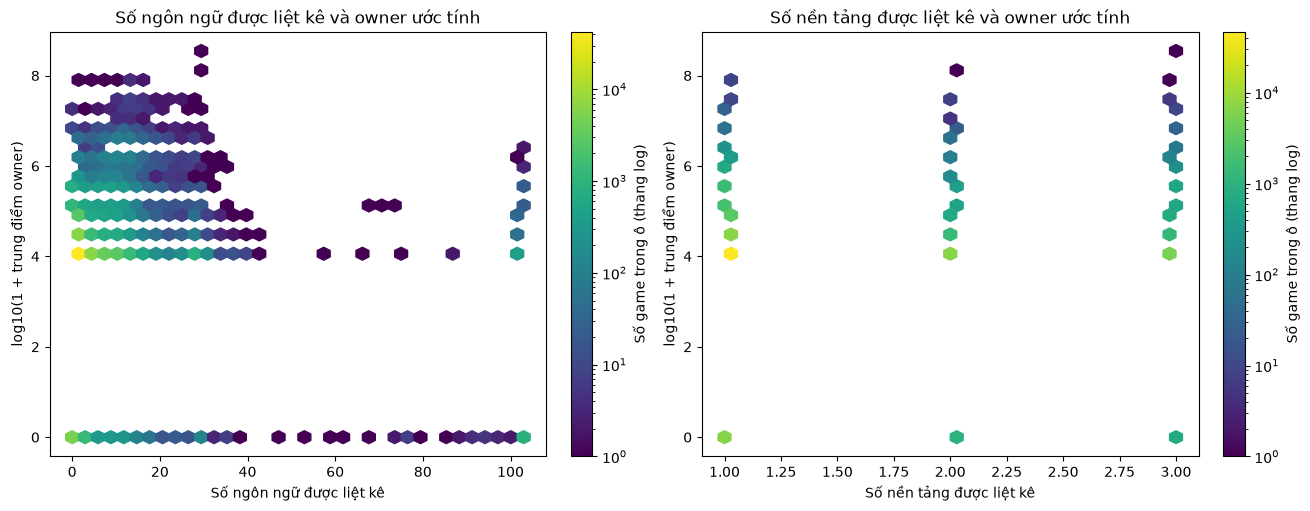

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, x_name, label in zip(axes, ["language_count", "platform_count"], ["Số ngôn ngữ được liệt kê", "Số nền tảng được liệt kê"]):
    hb = ax.hexbin(rq1[x_name], np.log10(rq1["owner_midpoint"] + 1), gridsize=35, mincnt=1, bins="log", cmap="viridis")
    ax.set(title=f"{label} và owner ước tính", xlabel=label, ylabel="log10(1 + trung điểm owner)")
    fig.colorbar(hb, ax=ax, label="Số game trong ô (thang log)")
plt.show()

**Nhận xét:** Màu đậm hơn nghĩa là có nhiều game hơn ở vùng đó. Đọc biểu đồ cùng bảng hệ số và khoảng tin cậy; biểu đồ không chứng minh nguyên nhân.

#### Biểu đồ 2: Association theo thể loại

- **Mục tiêu:** So sánh mối liên hệ giữa số ngôn ngữ/số hệ điều hành và số người sở hữu ước tính ở các thể loại phổ biến.
- **Loại:** Biểu đồ điểm; game đa thể loại có thể thuộc nhiều nhóm.

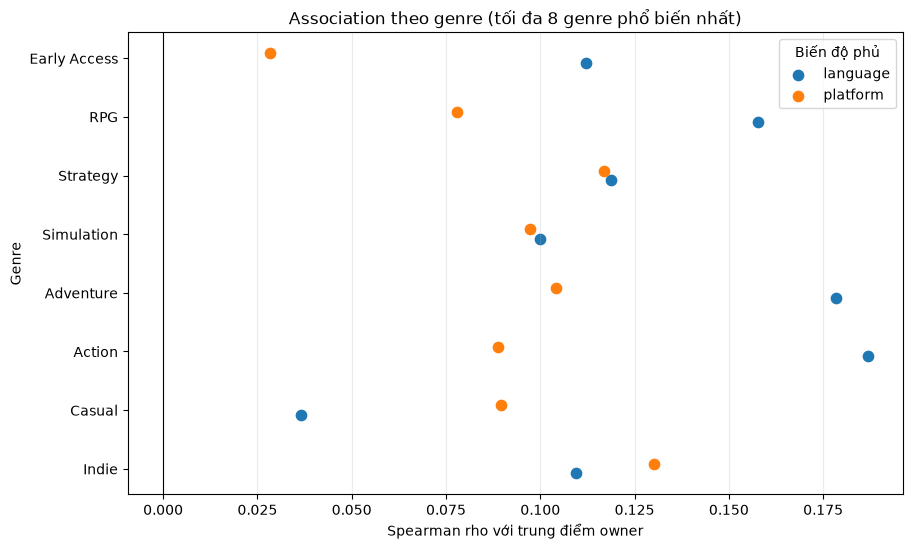

In [6]:
plot_data = pd.DataFrame(genre_correlations)
fig, ax = plt.subplots(figsize=(10, 6))
for i, x_name in enumerate(["language_count", "platform_count"]):
    part = plot_data.loc[plot_data["attribute"].eq(x_name)].set_index("genre").reindex(top_genres)
    ax.scatter(part["rho"], np.arange(len(top_genres)) + (i - 0.5) * 0.16, label=x_name.replace("_count", ""), s=55)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(np.arange(len(top_genres)), top_genres)
ax.set(xlabel="Spearman rho với trung điểm owner", ylabel="Genre", title="Association theo genre (tối đa 8 genre phổ biến nhất)")
ax.legend(title="Biến độ phủ")
ax.grid(axis="x", alpha=0.25)
plt.show()

**Nhận xét:** So sánh hệ số và số game trong bảng. Một game có thể xuất hiện ở nhiều thể loại; các yếu tố khác chưa được điều chỉnh cùng lúc.

### 10. Kết quả và thảo luận

**Kết quả chính:** Trong 89.618 game, số ngôn ngữ có liên hệ dương nhưng nhỏ với lượng người sở hữu ước tính (Spearman ρ = 0,153; khoảng tin cậy bootstrap 95%: 0,146–0,161). Số hệ điều hành cũng có liên hệ dương nhỏ (ρ = 0,108; khoảng tin cậy bootstrap 95%: 0,100–0,115). Hệ số càng gần 0 thì mối liên hệ càng yếu.

**Khác biệt giữa các nhóm:** Mối liên hệ giữa số ngôn ngữ và owner cao hơn ở Action (0,187) so với Casual (0,036). Theo tuổi game 0–5, trên 5–10 và trên 10 năm, hệ số lần lượt là 0,119; 0,272; 0,351. Đây là các so sánh riêng từng nhóm, chưa kiểm tra thống kê xem chênh lệch giữa các nhóm có chắc chắn hay không.

**Giả thuyết:** H1 có bằng chứng về mối liên hệ dương. H2 và H3 cho thấy hệ số khác nhau giữa các nhóm thể loại, tuổi và giá; cần thận trọng vì đây chưa phải kiểm định đầy đủ về chênh lệch giữa các nhóm.

**Tích hợp dữ liệu (D1):** Nối được 88.813 trong 89.618 game CSV (99,1%) với HF theo mã game; 805 game không khớp dùng số nền tảng từ CSV. Trong các game khớp, số nền tảng từ hai nguồn khác nhau ở 429 trường hợp (0,5%). Các bất đồng này được giữ theo nguồn HF cho mẫu đã khớp và cần được xem xét như giới hạn dữ liệu.

**Ý nghĩa:** Kết quả cho biết hai yếu tố có liên hệ trong dữ liệu, không chứng minh hỗ trợ thêm ngôn ngữ hoặc hệ điều hành làm tăng lượng người sở hữu.

### 11. Kiểm tra độ ổn định (D6)

Kết quả vẫn có cùng chiều khi đổi cách tính lượng người sở hữu. Với số ngôn ngữ, hệ số lần lượt là 0,180 (mức thấp), 0,153 (điểm giữa), 0,153 (mức cao), 0,195 khi bỏ khoảng `0–0`, và 0,153 sau khi giới hạn giá trị quá lớn. Với số hệ điều hành, các hệ số tương ứng là 0,118; 0,108; 0,108; 0,121; 0,108.

Khi chia tuổi game theo ba nhóm gần bằng nhau, hệ số số ngôn ngữ tăng từ 0,083 ở nhóm game trẻ lên 0,291 ở nhóm game lâu năm. Khoảng `0–0` chưa rõ ý nghĩa, nên chỉ thử riêng để xem kết quả có đổi không; không xem đây là quy tắc làm sạch mặc định.

### 12. Hạn chế

- Lượng người sở hữu là ước tính theo khoảng, không phải số đếm chính xác. Điểm giữa chỉ là cách đại diện cho khoảng đó.
- Chưa xác minh được ý nghĩa của khoảng `0–0`; cách hiểu khoảng này có thể ảnh hưởng kết quả.
- Danh sách ngôn ngữ trống được tính là 0 ngôn ngữ được liệt kê; điều đó không chắc có nghĩa game thật sự không hỗ trợ ngôn ngữ nào.
- Một game có thể thuộc nhiều thể loại, nên các nhóm thể loại có thể trùng nhau.
- HF parquet khớp 99,1% mã game trong CSV; một số mã không khớp và 429 game khớp có số nền tảng khác nhau giữa hai nguồn. Sự khác biệt có thể liên quan đến thời điểm hoặc cách ghi nhận, nhưng chưa xác định được nguyên nhân.
- Dữ liệu là ảnh chụp ở một thời điểm. Kết quả chỉ cho biết mối liên hệ, không chứng minh nguyên nhân.

### 13. Kết luận

Trong dữ liệu tích hợp, game có nhiều ngôn ngữ hoặc hệ điều hành được hỗ trợ thường có lượng người sở hữu ước tính cao hơn một chút; mức liên hệ thay đổi theo thể loại và tuổi game. Kết quả vẫn cùng chiều khi thay đổi cách tính owner. D1 được thực hiện bằng cách nối CSV chính với HF parquet và đối chiếu số nền tảng. Đây là các mối liên hệ mô tả, không chứng minh hỗ trợ thêm ngôn ngữ hoặc hệ điều hành làm tăng lượng người sở hữu.

## 3.4.2. Phân tích Câu hỏi nghiên cứu 2: Lượt đánh giá và tỷ lệ tích cực (RQ2)

### 1. Mục tiêu nghiên cứu

Câu hỏi nghiên cứu: **Quy mô người sở hữu ước tính và tuổi đời game có mối liên hệ như thế nào với số lượt đánh giá? Mối liên hệ giữa số lượt đánh giá và tỷ lệ đánh giá tích cực có khác nhau giữa các thể loại game hay không khi xem xét đồng thời quy mô sở hữu, tuổi game và các giá trị cực lớn?**

### 2. Động cơ nghiên cứu

Số lượt đánh giá cho biết mức độ người chơi đã để lại phản hồi cho một game; tỷ lệ đánh giá tích cực tóm tắt chiều hướng phản hồi. So sánh hai chỉ số theo quy mô sở hữu, tuổi game và thể loại giúp mô tả game nào có nhiều đánh giá hơn, và liệu mức độ tích cực có đi cùng số lượt đánh giá hay không. Phân tích ở cấp game nên không đại diện cho từng người chơi và không kết luận quan hệ nhân quả.

**Các bên quan tâm:** Nhà phát triển, nhà phát hành, nhóm chăm sóc cộng đồng, nhà phân tích danh mục game và người mua game.

**Giá trị thực tiễn:** Kết quả giúp so sánh mức độ phản hồi và tỷ lệ đánh giá tích cực giữa các game/thể loại, đồng thời xem mối liên hệ có còn sau khi tính đến quy mô sở hữu và tuổi game.

### 3. Thuộc tính sử dụng

| Thuộc tính | Nguồn dữ liệu | Vai trò trong phân tích |
|---|---|---|
| `appid` | CSV chính | Định danh game và đơn vị phân tích. |
| `num_reviews_total` | CSV chính | Số lượt đánh giá; giá trị `-1` không phải số đếm hợp lệ. |
| `pct_pos_total` | CSV chính | Tỷ lệ đánh giá tích cực; giá trị `-1` không phải tỷ lệ hợp lệ. |
| `estimated_owners`, `release_date` | CSV chính | Quy mô sở hữu ước tính và tuổi game dùng làm yếu tố giải thích/kiểm soát. |
| `genres` | CSV chính | Nhóm thể loại; một game có thể thuộc nhiều nhóm. |

### 4. Giả thuyết nghiên cứu

- **H1:** Số lượt đánh giá có mối liên hệ với quy mô sở hữu ước tính và tuổi game sau khi xem xét thể loại.
- **H2:** Mối liên hệ giữa số lượt đánh giá và tỷ lệ đánh giá tích cực khác nhau theo thể loại sau khi xem xét quy mô sở hữu và tuổi game.
- **H3:** Các mối liên hệ chính vẫn tương tự khi loại riêng 1% game có số lượt đánh giá cao nhất; đây là kiểm tra độ bền, không phải quy tắc xóa dữ liệu mặc định.

### 5. Tiêu chí chiều sâu phân tích dự kiến

| Tiêu chí | Phương pháp dự kiến | Mục tiêu |
|---|---|---|
| **D2 – Tái cấu trúc / Thời gian** | Tách `genres` thành bảng phụ để tóm tắt theo thể loại; giữ khóa game để một game không bị tính lặp trong mô hình tổng thể. | So sánh thể loại nhưng giữ đúng đơn vị phân tích. |
| **D3 – Biến dẫn xuất** | Dùng `log1p(num_reviews_total)` và `log1p(owner_midpoint)`; tính `game_age` đến 31/03/2025. | Giảm lệch phải ở biến đếm và quy mô sở hữu. |
| **D4 – Yếu tố liên quan** | Hồi quy ở cấp game, đồng thời đưa quy mô sở hữu, tuổi game và thể loại vào mô hình; mô hình tỷ lệ tích cực thêm tương tác giữa log lượt đánh giá và thể loại. | Ước lượng mối liên hệ có điều kiện, không diễn giải là nhân quả. |
| **D5 – Định lượng độ bất định** | OLS với sai số chuẩn HC3 và khoảng tin cậy 95%; báo cỡ mẫu và hệ số. | Thể hiện độ lớn và mức bất định, có xét phương sai sai số không đồng đều. |
| **D6 – Kiểm tra độ bền** | Lặp lại mô hình sau khi giới hạn ở 99% giá trị `num_reviews_total` thấp hơn. | Kiểm tra kết quả có bị chi phối bởi một số game có lượng đánh giá rất lớn hay không. |

### 6. Quy tắc xử lý và giới hạn

CSV có 89.618 game. `num_reviews_total` và `pct_pos_total` cùng được ghi `-1` ở 36.419 game. Đây không phải số đếm hay tỷ lệ hợp lệ, nên loại các dòng này khỏi mô hình, không đổi `-1` thành 0. `num_reviews_total` không khớp `positive + negative` ở phần lớn dòng; vì vậy dùng trực tiếp hai trường tổng hợp và không tự dựng lại tỷ lệ từ các cột thành phần. `estimated_owners` là khoảng ước tính; kết quả chỉ mô tả mối liên hệ ở cấp game. Các nhóm thể loại có thể chồng lấn.

In [7]:
from pathlib import Path
import ast
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw" / "steam_games_mar2025.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Không tìm thấy data/raw/steam_games_mar2025.csv từ thư mục hiện tại hoặc thư mục cha.")

rq2_columns = ["appid", "num_reviews_total", "pct_pos_total", "positive", "negative", "estimated_owners", "release_date", "genres"]
rq2_raw = pd.read_csv(project_root / "data" / "raw" / "steam_games_mar2025.csv", usecols=rq2_columns)
if rq2_raw["appid"].duplicated().any():
    raise ValueError("appid bị trùng; dừng để tránh tính một game nhiều lần trong phân tích tổng thể.")

for column in ["num_reviews_total", "pct_pos_total", "positive", "negative"]:
    rq2_raw[column] = pd.to_numeric(rq2_raw[column], errors="coerce")
valid_review_metrics = rq2_raw["num_reviews_total"].ge(0) & rq2_raw["pct_pos_total"].between(0, 100)
owner_bounds = rq2_raw["estimated_owners"].astype("string").str.extract(r"^\s*([\d,]+)\s*-\s*([\d,]+)\s*$")
rq2_raw["owner_low"] = pd.to_numeric(owner_bounds[0].str.replace(",", "", regex=False), errors="coerce")
rq2_raw["owner_high"] = pd.to_numeric(owner_bounds[1].str.replace(",", "", regex=False), errors="coerce")
rq2_raw["owner_midpoint"] = (rq2_raw["owner_low"] + rq2_raw["owner_high"]) / 2
rq2_raw["release_date_parsed"] = pd.to_datetime(rq2_raw["release_date"], errors="coerce")
rq2_raw["game_age"] = (pd.Timestamp("2025-03-31") - rq2_raw["release_date_parsed"]).dt.days / 365.2425

owner_valid = rq2_raw["owner_midpoint"].notna() & rq2_raw["owner_low"].le(rq2_raw["owner_high"])
date_valid = rq2_raw["game_age"].notna() & rq2_raw["game_age"].ge(0)
analysis_mask = valid_review_metrics & owner_valid & date_valid
rq2 = rq2_raw.loc[analysis_mask].copy()
if rq2.empty:
    raise ValueError("Không còn game có các trường hợp lệ để phân tích RQ2.")

def parse_genres(value):
    if isinstance(value, list):
        parsed = value
    elif pd.isna(value):
        return []
    else:
        parsed = ast.literal_eval(value)
    if not isinstance(parsed, (list, tuple)):
        raise ValueError(f"Danh sách thể loại không hợp lệ: {value!r}")
    return list(dict.fromkeys(parsed))

rq2["genre_list"] = rq2["genres"].map(parse_genres)
rq2["log_reviews"] = np.log1p(rq2["num_reviews_total"].to_numpy(dtype=float))
rq2["log_owners"] = np.log1p(rq2["owner_midpoint"].to_numpy(dtype=float))

valid_parts_match = rq2["num_reviews_total"].eq(rq2["positive"] + rq2["negative"])
input_checks = pd.DataFrame([
    {"Kiểm tra": "Tổng game trong CSV", "Kết quả": f"{len(rq2_raw):,}"},
    {"Kiểm tra": "Game có num_reviews_total = -1", "Kết quả": f"{int(rq2_raw['num_reviews_total'].eq(-1).sum()):,}"},
    {"Kiểm tra": "Game có pct_pos_total = -1", "Kết quả": f"{int(rq2_raw['pct_pos_total'].eq(-1).sum()):,}"},
    {"Kiểm tra": "Game có cả hai chỉ số hợp lệ", "Kết quả": f"{int(valid_review_metrics.sum()):,}"},
    {"Kiểm tra": "Game đưa vào mô hình sau khi kiểm tra owner/ngày", "Kết quả": f"{len(rq2):,}"},
    {"Kiểm tra": "Game hợp lệ mà num_reviews_total khớp positive + negative", "Kết quả": f"{int(valid_parts_match.sum()):,} / {len(rq2):,}"},
])
display(Markdown("#### Kiểm tra chất lượng và phạm vi mẫu"))
display(input_checks)
display(Markdown("Mã `-1` được xem là không có chỉ số hợp lệ, không đổi thành 0. Vì các cột `positive`/`negative` thường không khớp tổng lượt đánh giá, phân tích giữ nguyên `num_reviews_total` và `pct_pos_total` từ nguồn."))

#### Kiểm tra chất lượng và phạm vi mẫu

,Kiểm tra,Kết quả
0,Tổng game trong CSV,"89,618"
1,Game có num_reviews_total = -1,"36,419"
2,Game có pct_pos_total = -1,"36,419"
3,Game có cả hai chỉ số hợp lệ,"53,199"
4,Game đưa vào mô hình sau khi kiểm tra owner/ngày,"53,199"
5,Game hợp lệ mà num_reviews_total khớp positive...,"6,217 / 53,199"


Mã `-1` được xem là không có chỉ số hợp lệ, không đổi thành 0. Vì các cột `positive`/`negative` thường không khớp tổng lượt đánh giá, phân tích giữ nguyên `num_reviews_total` và `pct_pos_total` từ nguồn.

### 4. Khám phá dữ liệu

Tóm tắt phân phối lượt đánh giá và tỷ lệ tích cực trong nhóm có giá trị hợp lệ. Dùng tương quan Spearman để xem mối liên hệ đơn điệu giữa lượt đánh giá với quy mô sở hữu, tuổi game và tỷ lệ tích cực. Theo thể loại, báo cỡ mẫu, trung vị và tương quan; một game có thể xuất hiện ở nhiều thể loại.

In [8]:
from scipy.stats import spearmanr

summary = pd.DataFrame([
    {"Chỉ số": "Số lượt đánh giá", "Trung vị": rq2["num_reviews_total"].median(), "Phân vị 90%": rq2["num_reviews_total"].quantile(.90), "Phân vị 99%": rq2["num_reviews_total"].quantile(.99)},
    {"Chỉ số": "Tỷ lệ đánh giá tích cực (%)", "Trung vị": rq2["pct_pos_total"].median(), "Phân vị 90%": rq2["pct_pos_total"].quantile(.90), "Phân vị 99%": rq2["pct_pos_total"].quantile(.99)},
])
display(Markdown("**Tóm tắt trong nhóm có chỉ số hợp lệ:**"))
display(summary.round(1))

rho_rows = []
for label, other in [
    ("Quy mô sở hữu ước tính", rq2["owner_midpoint"]),
    ("Tuổi game (năm)", rq2["game_age"]),
    ("Tỷ lệ đánh giá tích cực (%)", rq2["pct_pos_total"]),
]:
    result = spearmanr(rq2["num_reviews_total"], other)
    rho_rows.append({"So sánh với số lượt đánh giá": label, "Spearman rho": result.statistic, "Số game": len(rq2)})
display(Markdown("**Tương quan Spearman toàn mẫu hợp lệ** (mô tả chưa kiểm soát các yếu tố khác):"))
display(pd.DataFrame(rho_rows).round(3))

top_genres = (
    rq2[["appid", "genre_list"]].explode("genre_list")
    .dropna(subset=["genre_list"])
    .groupby("genre_list")["appid"].nunique()
    .nlargest(8).index.tolist()
)
genre_rows = []
for genre in top_genres:
    subset = rq2.loc[rq2["genre_list"].map(lambda genres: genre in genres)]
    rho = spearmanr(subset["num_reviews_total"], subset["pct_pos_total"]).statistic
    genre_rows.append({
        "Thể loại": genre,
        "Số game hợp lệ": len(subset),
        "Trung vị lượt đánh giá": subset["num_reviews_total"].median(),
        "Trung vị tích cực (%)": subset["pct_pos_total"].median(),
        "Spearman rho: lượt đánh giá và % tích cực": rho,
    })
display(Markdown("**Mô tả theo 8 thể loại có nhiều game hợp lệ nhất:**"))
display(pd.DataFrame(genre_rows).round(2))

**Tóm tắt trong nhóm có chỉ số hợp lệ:**

,Chỉ số,Trung vị,Phân vị 90%,Phân vị 99%
0,Số lượt đánh giá,55.0,1330.2,33601.0
1,Tỷ lệ đánh giá tích cực (%),81.0,96.0,100.0


**Tương quan Spearman toàn mẫu hợp lệ** (mô tả chưa kiểm soát các yếu tố khác):

,So sánh với số lượt đánh giá,Spearman rho,Số game
0,Quy mô sở hữu ước tính,0.513,53199
1,Tuổi game (năm),0.184,53199
2,Tỷ lệ đánh giá tích cực (%),0.090,53199


**Mô tả theo 8 thể loại có nhiều game hợp lệ nhất:**

,Thể loại,Số game hợp lệ,Trung vị lượt đánh giá,Trung vị tích cực (%),Spearman rho: lượt đánh giá và % tích cực
0,Indie,37952,50.0,82.0,0.10
1,Adventure,22476,58.0,81.0,0.12
2,Action,21646,54.0,80.0,0.05
3,Casual,21572,42.0,82.0,0.08
4,Simulation,12555,68.0,77.0,0.20
5,RPG,10864,83.0,79.0,0.12
6,Strategy,10773,65.0,78.0,0.08
7,Free To Play,7460,68.0,80.0,0.04


### 5. Phân tích có kiểm soát và kiểm tra độ bền

Mô hình thứ nhất dự đoán `log1p(num_reviews_total)` theo `log1p(owner_midpoint)`, tuổi game và các cờ thể loại. Mô hình thứ hai dự đoán `pct_pos_total` theo log lượt đánh giá, quy mô sở hữu, tuổi game, thể loại và tương tác giữa log lượt đánh giá với thể loại. Hệ số tương tác cho biết mối liên hệ giữa lượt đánh giá với tỷ lệ tích cực có khác theo nhóm thể loại hay không.

Dùng sai số chuẩn HC3 và khoảng tin cậy 95%. Sau đó lặp lại hai mô hình khi bỏ 1% lượt đánh giá cao nhất để kiểm tra độ nhạy. Các thể loại có thể chồng lấn; kết quả là mối liên hệ ở cấp game, không phải tác động nhân quả.

**Mô hình số lượt đánh giá** (log1p; N=53,199; mô hình độ bền N=52,670; đã kiểm soát tuổi game và 6 thể loại):

,Yếu tố,"Hệ số, toàn bộ mẫu",KTC 95% dưới,KTC 95% trên,"Hệ số, bỏ 1% lượt đánh giá cao nhất",KTC 95% dưới (độ bền),KTC 95% trên (độ bền)
0,log1p quy mô sở hữu,0.1567,0.1506,0.1628,0.1333,0.1279,0.1387
1,Tuổi game (mỗi năm),0.0425,0.0375,0.0476,0.0458,0.0410,0.0505


**Mô hình tỷ lệ tích cực:** OLS có tương tác `log1p(lượt đánh giá) × thể loại`, đã kiểm soát quy mô sở hữu và tuổi game. Kiểm định đồng thời các tương tác: Wald chi-square=258.60, df=6, p=5.96e-53; sau khi bỏ 1% lượt đánh giá cao nhất: chi-square=225.27, df=6, p=7.81e-46. Bảng cho biết mức thay đổi ước tính theo mỗi lần lượt đánh giá tăng gấp đôi (xấp xỉ).

,"Thay đổi tỷ lệ tích cực (điểm %) khi lượt đánh giá tăng gấp đôi, xấp xỉ",KTC 95% dưới,KTC 95% trên,"Thay đổi tỷ lệ tích cực (điểm %) khi lượt đánh giá tăng gấp đôi, xấp xỉ (bỏ 1% cao nhất)",KTC 95% dưới (bỏ 1% cao nhất),KTC 95% trên (bỏ 1% cao nhất)
Thể loại,,,,,,
Indie,1.789,1.674,1.904,1.818,1.696,1.940
Adventure,1.570,1.437,1.703,1.646,1.502,1.789
Action,0.919,0.801,1.038,0.927,0.793,1.061
Casual,1.181,1.042,1.320,1.218,1.071,1.366
Simulation,1.902,1.752,2.052,1.964,1.803,2.126
RPG,1.204,1.053,1.355,1.224,1.061,1.386


**Độ bền của mối liên hệ lượt đánh giá – tỷ lệ tích cực:**

,Kiểm tra,Kết quả
0,Ngưỡng lượt đánh giá phân vị 99%,"33,601"
1,Số game sau khi bỏ 1% lượt đánh giá cao nhất,"52,670"
2,"Wald p cho tương tác thể loại, toàn bộ mẫu",5.96e-53
3,"Wald p cho tương tác thể loại, sau khi bỏ 1% c...",7.81e-46


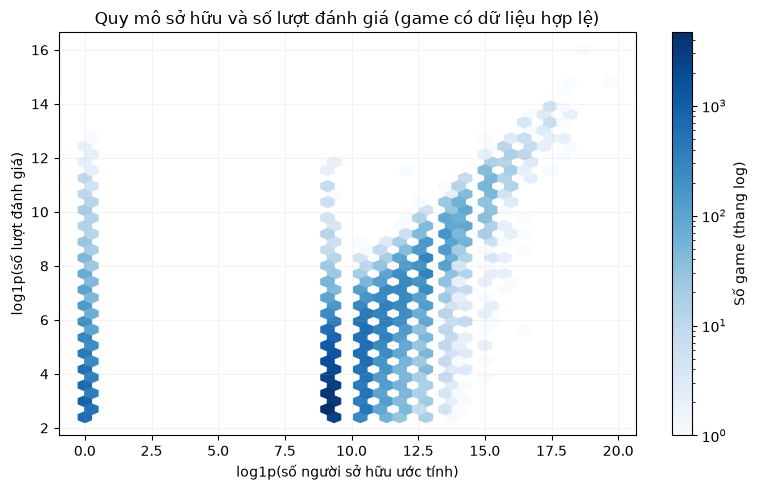

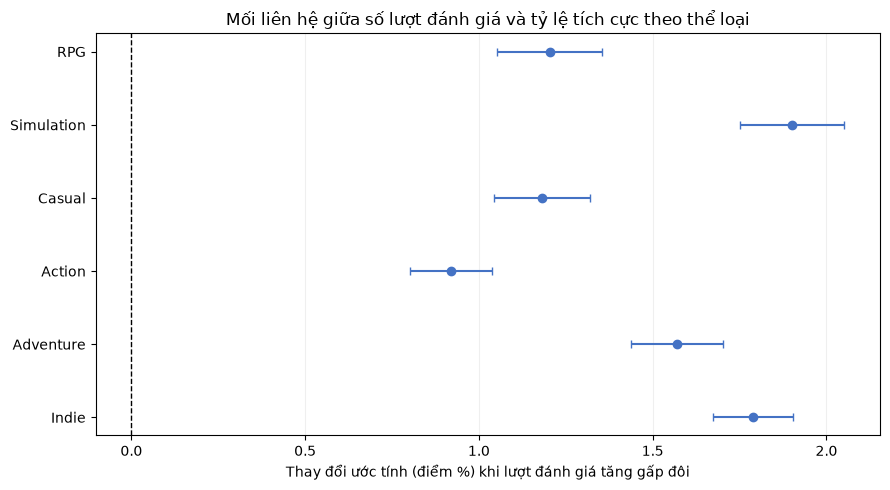

In [9]:
from scipy.stats import chi2
import matplotlib.pyplot as plt

model_genres = top_genres[:6]
genre_matrix = np.column_stack([
    rq2["genre_list"].map(lambda genres, g=genre: g in genres).to_numpy(dtype=float)
    for genre in model_genres
])
review_values = rq2["num_reviews_total"].to_numpy(dtype=float)
log_review_values = np.log1p(review_values)
log_owner_values = rq2["log_owners"].to_numpy(dtype=float)
age_values = rq2["game_age"].to_numpy(dtype=float)
positive_pct_values = rq2["pct_pos_total"].to_numpy(dtype=float)

def fit_ols_hc3(design, outcome):
    design = np.asarray(design, dtype=float)
    outcome = np.asarray(outcome, dtype=float)
    bread = np.linalg.pinv(design.T @ design)
    coefficients = bread @ design.T @ outcome
    residuals = outcome - design @ coefficients
    leverage = np.sum((design @ bread) * design, axis=1)
    adjusted_residuals = residuals / np.maximum(1 - leverage, 1e-10)
    meat = design.T @ (design * np.square(adjusted_residuals)[:, None])
    covariance = bread @ meat @ bread
    standard_errors = np.sqrt(np.maximum(np.diag(covariance), 0))
    return coefficients, standard_errors, covariance

def build_models(mask):
    mask = np.asarray(mask, dtype=bool)
    genres = genre_matrix[mask]
    log_reviews = log_review_values[mask]
    volume_design = np.column_stack([
        np.ones(mask.sum()), log_owner_values[mask], age_values[mask], genres,
    ])
    volume = fit_ols_hc3(volume_design, log_reviews)
    rating_design = np.column_stack([
        np.ones(mask.sum()), log_reviews, log_owner_values[mask], age_values[mask],
        genres, log_reviews[:, None] * genres,
    ])
    rating = fit_ols_hc3(rating_design, positive_pct_values[mask])
    interaction_start = 4 + len(model_genres)
    interaction_slice = slice(interaction_start, interaction_start + len(model_genres))
    interaction_beta = rating[0][interaction_slice]
    interaction_cov = rating[2][interaction_slice, interaction_slice]
    interaction_rank = np.linalg.matrix_rank(interaction_cov)
    wald = float(interaction_beta @ np.linalg.pinv(interaction_cov) @ interaction_beta)
    wald_p = float(chi2.sf(wald, interaction_rank))
    return volume, rating, wald, interaction_rank, wald_p

all_mask = np.ones(len(rq2), dtype=bool)
volume_all, rating_all, wald_all, wald_df_all, wald_p_all = build_models(all_mask)
q99_review_count = float(np.quantile(review_values, .99))
trim_mask = review_values <= q99_review_count
volume_trim, rating_trim, wald_trim, wald_df_trim, wald_p_trim = build_models(trim_mask)

volume_rows = []
for label, index in [("log1p quy mô sở hữu", 1), ("Tuổi game (mỗi năm)", 2)]:
    beta, se = volume_all[0][index], volume_all[1][index]
    beta_trim, se_trim = volume_trim[0][index], volume_trim[1][index]
    volume_rows.append({
        "Yếu tố": label,
        "Hệ số, toàn bộ mẫu": beta,
        "KTC 95% dưới": beta - 1.96 * se,
        "KTC 95% trên": beta + 1.96 * se,
        "Hệ số, bỏ 1% lượt đánh giá cao nhất": beta_trim,
        "KTC 95% dưới (độ bền)": beta_trim - 1.96 * se_trim,
        "KTC 95% trên (độ bền)": beta_trim + 1.96 * se_trim,
    })
display(Markdown(f"**Mô hình số lượt đánh giá** (log1p; N={len(rq2):,}; mô hình độ bền N={int(trim_mask.sum()):,}; đã kiểm soát tuổi game và 6 thể loại):"))
display(pd.DataFrame(volume_rows).round(4))


def genre_slopes(model):
    coefficients, _, covariance = model
    interaction_start = 4 + len(model_genres)
    rows = []
    for j, genre in enumerate(model_genres):
        contrast = np.zeros(len(coefficients))
        contrast[1] = np.log(2)
        contrast[interaction_start + j] = np.log(2)
        effect = float(contrast @ coefficients)
        se = float(np.sqrt(max(contrast @ covariance @ contrast, 0)))
        rows.append({
            "Thể loại": genre,
            "Thay đổi tỷ lệ tích cực (điểm %) khi lượt đánh giá tăng gấp đôi, xấp xỉ": effect,
            "KTC 95% dưới": effect - 1.96 * se,
            "KTC 95% trên": effect + 1.96 * se,
        })
    return pd.DataFrame(rows)

slope_all = genre_slopes(rating_all).set_index("Thể loại")
slope_trim = genre_slopes(rating_trim).set_index("Thể loại")
slope_results = slope_all.join(slope_trim, lsuffix="", rsuffix=" (bỏ 1% cao nhất)")
display(Markdown(
    "**Mô hình tỷ lệ tích cực:** OLS có tương tác `log1p(lượt đánh giá) × thể loại`, đã kiểm soát quy mô sở hữu và tuổi game. "
    f"Kiểm định đồng thời các tương tác: Wald chi-square={wald_all:.2f}, df={wald_df_all}, p={wald_p_all:.3g}; "
    f"sau khi bỏ 1% lượt đánh giá cao nhất: chi-square={wald_trim:.2f}, df={wald_df_trim}, p={wald_p_trim:.3g}. "
    "Bảng cho biết mức thay đổi ước tính theo mỗi lần lượt đánh giá tăng gấp đôi (xấp xỉ)."
))
display(slope_results.round(3))

robustness = pd.DataFrame([
    {"Kiểm tra": "Ngưỡng lượt đánh giá phân vị 99%", "Kết quả": f"{q99_review_count:,.0f}"},
    {"Kiểm tra": "Số game sau khi bỏ 1% lượt đánh giá cao nhất", "Kết quả": f"{int(trim_mask.sum()):,}"},
    {"Kiểm tra": "Wald p cho tương tác thể loại, toàn bộ mẫu", "Kết quả": f"{wald_p_all:.3g}"},
    {"Kiểm tra": "Wald p cho tương tác thể loại, sau khi bỏ 1% cao nhất", "Kết quả": f"{wald_p_trim:.3g}"},
])
display(Markdown("**Độ bền của mối liên hệ lượt đánh giá – tỷ lệ tích cực:**"))
display(robustness)

fig, ax = plt.subplots(figsize=(8, 5))
hexbin = ax.hexbin(log_owner_values, log_review_values, gridsize=40, mincnt=1, bins="log", cmap="Blues")
ax.set(title="Quy mô sở hữu và số lượt đánh giá (game có dữ liệu hợp lệ)", xlabel="log1p(số người sở hữu ước tính)", ylabel="log1p(số lượt đánh giá)")
fig.colorbar(hexbin, ax=ax, label="Số game (thang log)")
ax.grid(alpha=.15)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
plot_data = slope_all.reset_index()
centers = plot_data["Thay đổi tỷ lệ tích cực (điểm %) khi lượt đánh giá tăng gấp đôi, xấp xỉ"].to_numpy()
low = plot_data["KTC 95% dưới"].to_numpy()
high = plot_data["KTC 95% trên"].to_numpy()
y_pos = np.arange(len(plot_data))
ax.errorbar(centers, y_pos, xerr=[centers - low, high - centers], fmt="o", color="#4472C4", capsize=3)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set(yticks=y_pos, yticklabels=plot_data["Thể loại"], title="Mối liên hệ giữa số lượt đánh giá và tỷ lệ tích cực theo thể loại", xlabel="Thay đổi ước tính (điểm %) khi lượt đánh giá tăng gấp đôi", ylabel="")
ax.grid(axis="x", alpha=.2)
plt.tight_layout()
plt.show()

### 6. Kết quả và thảo luận

- Dùng bảng kiểm tra đầu vào để nêu số game có chỉ số hợp lệ và số game bị loại do sentinel `-1`; không gọi các giá trị `-1` là 0.
- Đọc tương quan Spearman như mối liên hệ đơn điệu chưa kiểm soát. Đọc mô hình lượt đánh giá theo hệ số của log quy mô sở hữu và tuổi game sau khi kiểm soát thể loại.
- Mô hình tương tác cho biết mối liên hệ giữa số lượt đánh giá và tỷ lệ tích cực có thay đổi theo thể loại hay không sau khi kiểm soát quy mô sở hữu/tuổi. Khoảng tin cậy không thay thế ý nghĩa thực tiễn; các thể loại có thể chồng lấn.
- So sánh toàn mẫu với mô hình bỏ 1% lượt đánh giá cao nhất. Nếu dấu và độ lớn hệ số tương tự thì kết quả ít nhạy hơn với một số game cực lớn; vẫn không suy ra quan hệ nhân quả.

### 7. Hạn chế và kết luận

Dữ liệu chỉ có thống kê tổng hợp theo game. Sentinel `-1` khiến khoảng 40,6% game không có chỉ số đánh giá hợp lệ; không thể suy rộng kết quả mô hình cho nhóm đó nếu chưa xác minh ý nghĩa trường dữ liệu. `estimated_owners` là khoảng ước tính; tỷ lệ tích cực là giá trị nguồn cung cấp. Các cột `positive`/`negative` không khớp `num_reviews_total` ở đa số game nên không dùng để dựng lại tỷ lệ. Một game có thể có nhiều thể loại; các nhóm không độc lập. Mô hình quan sát không chứng minh rằng nhiều owner hoặc nhiều lượt đánh giá gây ra tỷ lệ tích cực cao hơn.

Kết luận cần dựa trên hệ số và khoảng tin cậy được notebook tính ở trên: mô tả mối liên hệ của lượt đánh giá với quy mô sở hữu/tuổi game, sau đó xem xét tương tác theo thể loại và độ bền khi loại riêng 1% lượt đánh giá cao nhất. Không kết luận về hành vi của từng người chơi.